**Neural Network + T2: 3 Hidden Layers (128, 64, 32)**

This notebook trains **MLP with transformation T2** for 6 values of `alpha` (6 of our 72 models). It uses the shared splits (`data/processed/`), preprocessing (`src/preprocessing.py`) and evaluation (`src/evaluation.py`), so the results can be merged with the other notebooks. We only use train and validation here; the test set is used once at the end of the project.

**Neural network** (`MLPClassifier`): each hidden layer computes $h = \text{ReLU}(W x + b)$, where ReLU sets negatives to 0, and the output layer gives $P(\text{attack})$. The hidden layers **learn their own features**, so for the MLP the architecture plays the role of the transformation.

**Regularization:** sklearn adds an L2 penalty on all weights to the log-loss:

$$\text{log-loss} + \frac{\alpha}{2} \lVert W \rVert^2$$

Here it's the other way around from `C`: **large `alpha` ---> strong regularization** (small weights, smoother function), **small `alpha` ---> weak regularization**. We also use `early_stopping=True`: 10% of the training rows are held out inside the MLP, and training stops when the score on them stops improving. This is a second form of regularization.

**1. Setup**

In [1]:
import sys
sys.path.append("..") # so we can import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.neural_network import MLPClassifier

from src.preprocessing import RANDOM_STATE, build_preprocessor, load_split
from src.evaluation import evaluate, plot_sweep, attack_recall, RESULTS

FIGS = RESULTS.parent / "figures"
RESULTS.mkdir(exist_ok=True)

X_train, y_train, cat_train = load_split("train")
X_val, y_val, cat_val = load_split("val")
print("train:", X_train.shape, " val:", X_val.shape)

train: (24000, 41)  val: (6000, 41)


**2. The architecture: 3 hidden layers (128, 64, 32)**

This is our **deepest** network. Each layer builds features out of the previous layer's features, so deeper networks can learn more complex combinations. The number of parameters per layer is (inputs x outputs) + outputs (weights + biases).

**Why do we do this?**: We compare it with T3 (one wide layer of 256), which has almost the same number of parameters ---> any difference comes from **deep vs wide**, not from model size

In [2]:
LAYERS = (128, 64, 32)
n_in = build_preprocessor().fit(X_train).transform(X_train.head(1)).shape[1]
sizes = [n_in, *LAYERS, 1]

for a, b in zip(sizes, sizes[1:]):
    print(f"{a:>4} ---> {b:<4}: {a * b + b:>6,} parameters")
print("total:", sum(a * b + b for a, b in zip(sizes, sizes[1:])))

  73 ---> 128 :  9,472 parameters
 128 ---> 64  :  8,256 parameters
  64 ---> 32  :  2,080 parameters
  32 ---> 1   :     33 parameters
total: 19841


The network has 19,841 parameters in total, and almost half of them (9,472) sit in the first layer, where the 73 inputs connect to 128 neurons. After that the layers get smaller (128 ---> 64 ---> 32), so the network works like a funnel: it first builds lots of combinations of the input features, then squeezes them down into fewer, more abstract ones before making the final prediction.

To put the size in perspective, our biggest logistic regression (LR T3) only had 815 weights, so this network has about 24 times more. With only around 21,600 rows actually used for training (early stopping keeps 10% aside), that's roughly one training row per parameter, so we expected this model to be able to overfit if we didn't regularize it.

**3. The pipeline**

The full pipeline: shared preprocessing (73 features) ---> MLP with hidden layers (128, 64, 32).

**MLP settings:** we kept sklearn's defaults for everything except the architecture and `alpha`:

| Setting | Value |
|---|---|
| Hidden activation | ReLU |
| Output | sigmoid (gives $P(\text{attack})$) |
| Optimizer | Adam, learning rate 0.001 |
| Batch size | 200 |
| Early stopping | 10% of training held out, stop after 10 epochs without improvement |
| Random state | 42 |

We kept ReLU ($\max(0, z)$) because this is our deepest network, and ReLU avoids vanishing gradients: its slope is 1 for any positive input, so the gradient doesn't shrink as it goes back through the 3 layers like it would with sigmoid or tanh. It's also very cheap to compute, which keeps training fast.

In [3]:
def build(alpha):
    return make_pipeline(build_preprocessor(),
                         MLPClassifier(hidden_layer_sizes=LAYERS, alpha=alpha,
                                       early_stopping=True, random_state=RANDOM_STATE))

**4. Regularization sweep**

We train one model for each of the 6 values of `alpha` (larger `alpha` = stronger regularization). Every model is fit on the 24,000 training rows and scored on both train and validation. `f1_gap` = train F1 - validation F1: a big gap means overfitting, while low F1 on both means underfitting.

In [4]:
GRID = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1]
rows, fitted = [], {} # fitted keeps each trained pipeline, so we don't have to retrain the best one

for value in GRID:
    pipe = build(value)
    rows.append(evaluate(pipe, "MLP", "T2", "alpha", value, X_train, y_train, X_val, y_val))
    fitted[value] = pipe
    print(f"alpha={value:g}: val F1 = {rows[-1]['val_f1']:.4f}, fit time = {rows[-1]['fit_time_s']}s")

results = pd.DataFrame(rows)
results["f1_gap"] = results["train_f1"] - results["val_f1"]
results.drop(columns=["model", "transformation", "param"]).round(4)

alpha=1e-05: val F1 = 0.9157, fit time = 4.46s
alpha=0.0001: val F1 = 0.9165, fit time = 5.08s
alpha=0.001: val F1 = 0.9174, fit time = 4.75s
alpha=0.01: val F1 = 0.9135, fit time = 5.46s
alpha=0.1: val F1 = 0.9174, fit time = 3.57s
alpha=1: val F1 = 0.9185, fit time = 8.38s


,value,train_precision,train_recall,train_f1,train_fpr,val_precision,val_recall,val_f1,val_fpr,fit_time_s,converged,f1_gap
0,0.0000,0.9280,0.9288,0.9284,0.0776,0.9128,0.9186,0.9157,0.0945,4.46,True,0.0127
1,0.0001,0.9301,0.9257,0.9279,0.0748,0.9170,0.9161,0.9165,0.0893,5.08,True,0.0114
2,0.0010,0.9303,0.9258,0.9280,0.0747,0.9174,0.9174,0.9174,0.0889,4.75,True,0.0107
3,0.0100,0.9335,0.9215,0.9274,0.0707,0.9165,0.9106,0.9135,0.0893,5.46,True,0.0139
4,0.1000,0.9031,0.9496,0.9258,0.1097,0.8983,0.9373,0.9174,0.1142,3.57,True,0.0084
5,1.0000,0.9026,0.9486,0.9251,0.1101,0.8960,0.9421,0.9185,0.1176,8.38,True,0.0066


**5. Validation curve**

Left: train F1 (dashed) vs validation F1 (solid). Right: validation precision, recall and false positive rate, to see what the regularization trades off.

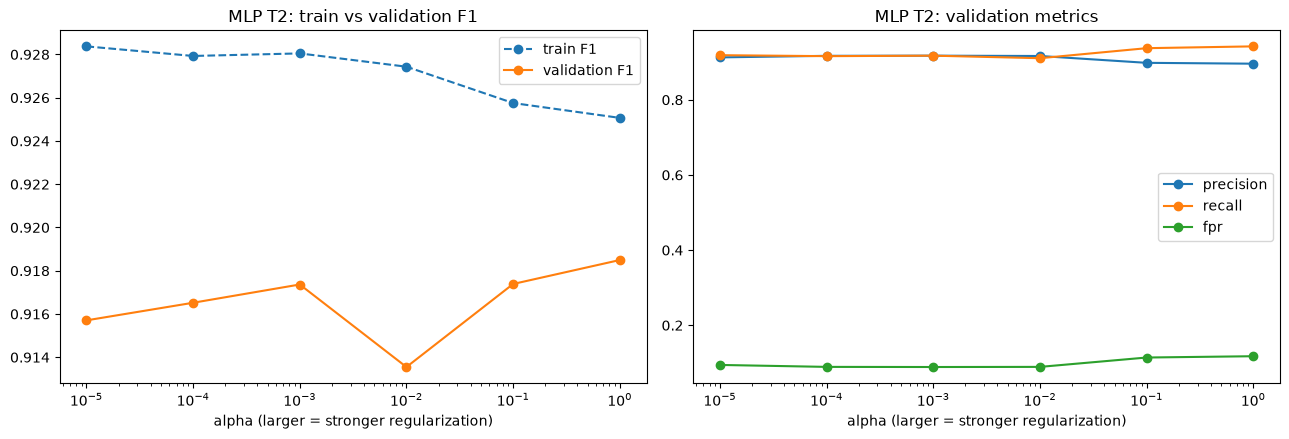

In [5]:
plot_sweep(results, "MLP T2", FIGS / "curve_mlp_t2_deep.png")

How did training go for each `alpha`? Left: the training loss per epoch. Right: the score on the 10% held out for early stopping. Training stops 10 epochs after that score stops improving.

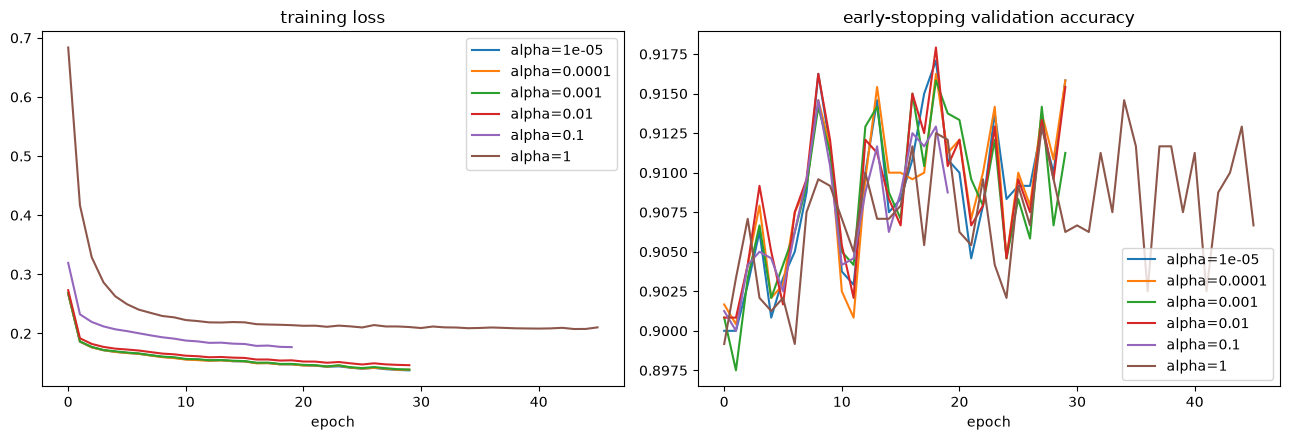

{'1e-05': 30, '0.0001': 30, '0.001': 30, '0.01': 30, '0.1': 20, '1': 46} <--- epochs trained per alpha


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for value, pipe in fitted.items():
    mlp = pipe[-1]
    axes[0].plot(mlp.loss_curve_, label=f"alpha={value:g}")
    axes[1].plot(mlp.validation_scores_, label=f"alpha={value:g}")
axes[0].set_title("training loss")
axes[1].set_title("early-stopping validation accuracy")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

print({f"{v:g}": p[-1].n_iter_ for v, p in fitted.items()}, "<--- epochs trained per alpha")

Honestly, `alpha` barely changed anything here. Validation F1 stays between 0.9135 and 0.9185 across all six values, with no clear trend. The best one is `alpha` = 1 (0.9185), which is at the edge of the grid, but it's only 0.001 better than `alpha` = 0.001 and 0.1. That's smaller than how much the score jumps around between epochs (see the right plot), so we didn't think extending the grid was worth it.

Where `alpha` does make a difference is the train/validation gap. With little regularization the gap is around 0.011 to 0.014, which is mild overfitting, and at `alpha` = 1 it shrinks to 0.0066. The training F1 goes down a bit while validation stays the same, which is what regularization is supposed to do. The loss curves show the same thing: with `alpha` = 1 the training loss levels off around 0.21 instead of 0.14, because the network isn't allowed to fit the training data as closely.

The more interesting part is what happens between `alpha` = 0.01 and 0.1. Below that point, the model is more careful about calling something an attack: precision is around 0.917 and FPR is only about 0.089, the lowest false alarm rate we've seen so far. Above it, the model flags more flows as attacks, so recall goes up to 0.94 but FPR jumps to 0.114 to 0.118. So F1 ends up almost the same, but the kind of mistakes the model makes changes.

**Why does this matter?**: If we cared more about false alarms than F1, `alpha` = 0.001 would actually be the better pick (FPR 0.089 vs 0.118, for only 0.001 less F1) ---> another reason to look at a threshold or FPR-based selection later, not just F1.

**6. The best setting**

We pick the `alpha` with the highest validation F1. If it is at the edge of the grid, the best value might be outside it, and we should consider extending the grid.

In [7]:
best = results.loc[results["val_f1"].idxmax()]
best_model = fitted[best["value"]]
print(f"best alpha = {best['value']:g}: val F1 = {best['val_f1']:.4f}, precision = {best['val_precision']:.4f}, "
      f"recall = {best['val_recall']:.4f}, FPR = {best['val_fpr']:.4f}")
if best["value"] in (GRID[0], GRID[-1]):
    print("the best value is at the edge of the grid ---> consider extending it")

best alpha = 1: val F1 = 0.9185, precision = 0.8960, recall = 0.9421, FPR = 0.1176
the best value is at the edge of the grid ---> consider extending it


The confusion matrix on the validation set: the top-right cell is false alarms (normal flagged as attack), the bottom-left cell is missed attacks.

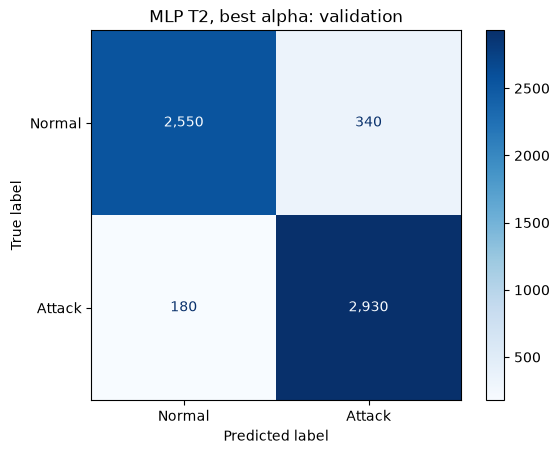

In [8]:
pred_val = best_model.predict(X_val)
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, display_labels=["Normal", "Attack"], cmap="Blues", values_format=",")
plt.title("MLP T2, best alpha: validation")
plt.savefig(FIGS / "confusion_mlp_t2_deep.png", dpi=150, bbox_inches="tight")
plt.show()

Which attack types does the best model miss? (On validation only, the test set stays untouched.)

In [9]:
attack_recall(y_val, pred_val, cat_val)

,rows,caught,missed,recall
type,,,,
Fuzzers,899,747,152,0.831
Analysis,89,83,6,0.933
Shellcode,61,60,1,0.984
Exploits,1105,1091,14,0.987
Backdoor,85,84,1,0.988
Reconnaissance,419,414,5,0.988
Generic,233,232,1,0.996
DoS,212,212,0,1.000
Worms,7,7,0,1.000


The best model (`alpha` = 1) makes 340 false alarms (11.8% of normal flows) and misses 180 attacks (5.8%). That's almost the same as LR T3 (335 false alarms, 188 misses), even though this network has about 24 times more parameters. So the extra depth didn't really buy us anything on this data.

Fuzzers are again the main problem: 152 of them are missed (recall 83.1%), which is 84% of all the attacks this model misses. Every other type is caught at 93% or better, and DoS and Worms are caught completely.

This is pretty much the same Fuzzers result we got with both logistic regression models, and now with a much more flexible model too. So we're fairly convinced the issue isn't the model. Fuzzers just look like normal traffic in these flow features, which is what the EDA suggested, and no amount of extra layers can separate two things that look identical in the input.

**7. Save the results**

We save the 6 rows to `results/mlp_t2_deep.csv`, so they can be merged with the other notebooks into the 72-row results table.

In [10]:
results.to_csv(RESULTS / "mlp_t2_deep.csv", index=False)
print("saved", len(results), "rows to", RESULTS / "mlp_t2_deep.csv")

saved 6 rows to /Users/nerominh/Documents/Fall 2026/Machine Learning/Network Fraud Detection/results/mlp_t2_deep.csv
